# Bl: one number, two jobs

**Written by Claude (Anthropic), 2026-10-25 14:06.** Capture is doc's proposed name, posited and up for testing. The words and code are Claude's.

Bl is B times l: the field in a loudspeaker's magnet gap, times the length of wire sitting in it. The l is a lowercase L, for length, not an I.

AP physics already has it, twice. A wire carrying a current across a field gets pushed, F = BIL. A wire moving across a field has a voltage along it, ℰ = BLv. The two formulas share a factor, BL. A speaker's spec sheet pulls that factor out and calls it Bl, the force factor. It's the push per amp, and it's the voltage per speed, and it's the same number both ways.

In [1]:
from speaker import Speaker, wire, bl, force, voltage, flux_captured, drag, ring, q_electrical, q_mechanical, OPEN, SHORT
from view import motor_still, ringdown_still
from panel import explore

s = Speaker()      # 1 T in the gap, 64 windings at 2 cm, 6 Ω, 20 g moving, 1250 N/m spring

## Where the B and the l are

Here's the motor cut in half along its axis. The magnet leaves a ring-shaped gap, and the field across the gap points straight out from the axis, all the way round. The coil sits in the gap, wound around the axis.

So everywhere along the coil, the wire crosses the field at right angles: around crossed with out is along. Every bit of wire gets pushed the same way, along the axis. That's why the whole length of wire counts, and why the cone moves straight in and out.

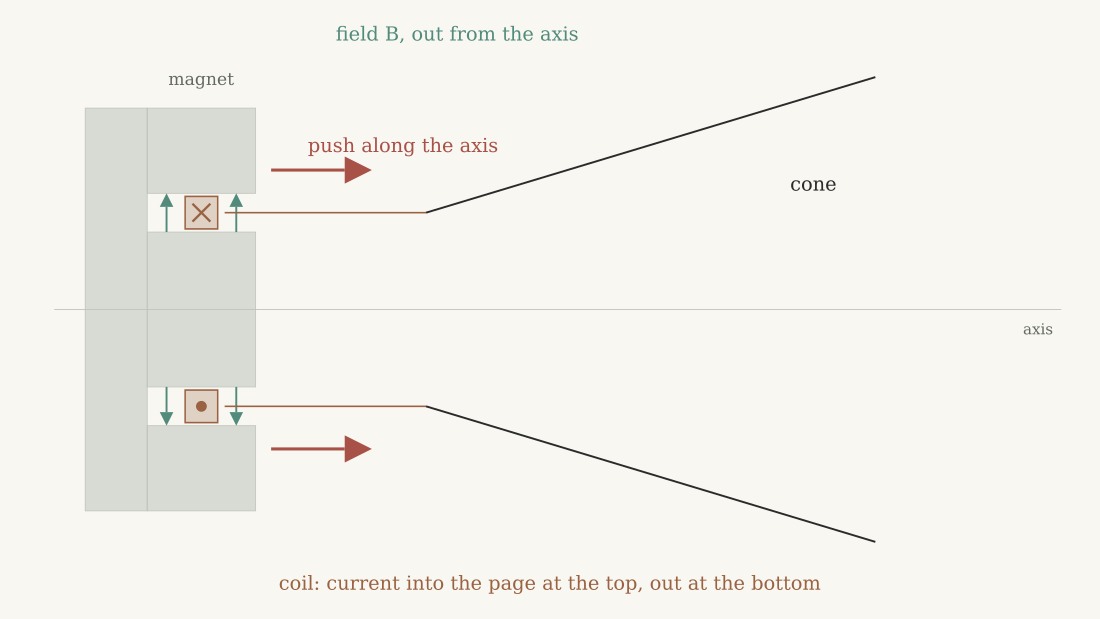

In [2]:
motor_still(current=1)

Run the current the other way, and the push turns around with it:

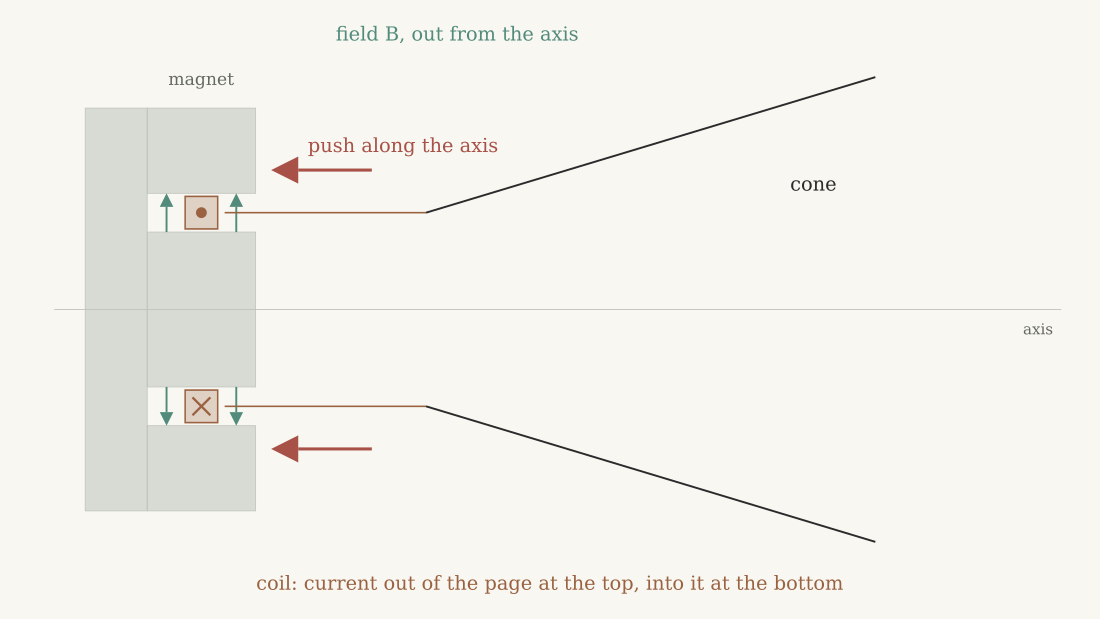

In [3]:
motor_still(current=-1)

## How long l is

Each winding is a turn at the coil's radius. A turn is τ, about 6.3 radians, so one winding at 2 cm is about 0.13 m of wire. The 64 windings make about 8 m, and 1 T across 8 m is a Bl of about 8 T·m.

In [4]:
print(f'wire in the gap  {wire(s):.3g} m')
print(f'Bl               {bl(s):.3g} T·m')

wire in the gap  8.04 m
Bl               8.04 T·m


## Measure it as a push

Lay the speaker on its back and set a 10 g washer on the cone. Its weight, 0.1 N, sinks the cone a little against the spring. Now run a small DC current through the coil until the cone comes back up to where it was. The push per amp is Bl, so it takes 0.1 N on 8 T·m, about 12 mA.

In [5]:
weight = 0.010 * 10                     # N
sink = weight / s.stiffness               # m
current = weight / bl(s)                  # A
print(f'the washer sinks the cone {1000*sink:.2g} mm')
print(f'{1000*current:.3g} mA lifts it back:  Bl of that current is {force(s, current):.3g} N')

the washer sinks the cone 0.08 mm
12.4 mA lifts it back:  Bl of that current is 0.1 N


## Measure it as a voltage

Now put a voltmeter on the leads and push the cone in, steadily, at 0.1 m/s. The speaker is a microphone. The voltage per speed is Bl, so it reads about 0.8 V.

In [6]:
print(f'{voltage(s, 0.1):.2g} V at 0.1 m/s')

0.8 V at 0.1 m/s


## Why it's the same number

When the coil moves a short way, every bit of the wire sweeps across the field. The whole wire sweeps out a band, l long and as wide as the move, and the field through that band is flux the coil has captured. So Bl is the flux captured per meter the coil moves: a T·m is a Wb/m.

The two jobs then come from the same two pieces of physics as a motor's capture. The voltage is the rate of flux captured, so Bl of the speed is the voltage. And the energy balance says the voltage of the current all goes into pushing the cone, so the push at the speed equals the voltage of the current. That makes Bl of the current the push.

Capture is this per radian of turning. Bl is it per meter of sliding.

In [7]:
move = 0.001                              # m, in 0.01 s
print(f'flux captured over {1000*move:g} mm:   {flux_captured(s, move):.3g} Wb')
print(f'that much per 0.01 s:      {flux_captured(s, move)/0.01:.3g} V')
print(f'the voltage at 0.1 m/s:    {voltage(s, 0.1):.3g} V')
i, v = 0.3, 0.1
print(f'push at speed {force(s, i)*v:.3g} W  =  voltage of current {voltage(s, v)*i:.3g} W')

flux captured over 1 mm:   0.00804 Wb
that much per 0.01 s:      0.804 V
the voltage at 0.1 m/s:    0.804 V
push at speed 0.241 W  =  voltage of current 0.241 W


## A winch is a speaker with a drum

Codex's winch had a capture of 0.5 Wb/rad on a 0.05 m drum. Seen from the cable, that's 0.5 on 0.05, a Bl of 10 Wb/m: 10 N per amp, and 10 V per m/s of cable. Its 2 A held the 20 N weight, and its cable rising at 0.8 m/s set up 8 V.

A loudspeaker is the same machine with the drum unrolled: the coil runs straight along the axis, not around a shaft.

In [8]:
capture, drum = 0.5, 0.05
print(f'the winch, seen from its cable: Bl = {capture/drum:g} Wb/m')
print(f'2 A pushes {capture/drum*2:g} N;  0.8 m/s sets up {capture/drum*0.8:g} V')

the winch, seen from its cable: Bl = 10 Wb/m
2 A pushes 20 N;  0.8 m/s sets up 8 V


## What Bl is for: the tap

Tap the cone. With the leads open, no current can flow, and only the suspension's own losses slow the cone. It rings on its spring.

Short the leads, which is about what a good amplifier's output looks like to a speaker, and Bl acts twice. The moving cone captures a voltage, the voltage drives a current around the coil, and the current's Bl pushes back on the cone. That drag is Bl² over the circuit's resistance: 8² on 6 Ω is about 11 N per m/s, ten times the suspension's own 1. The cone thuds instead of ringing.

You can try this on any woofer: tap the cone with the leads apart, then twist them together and tap it again.

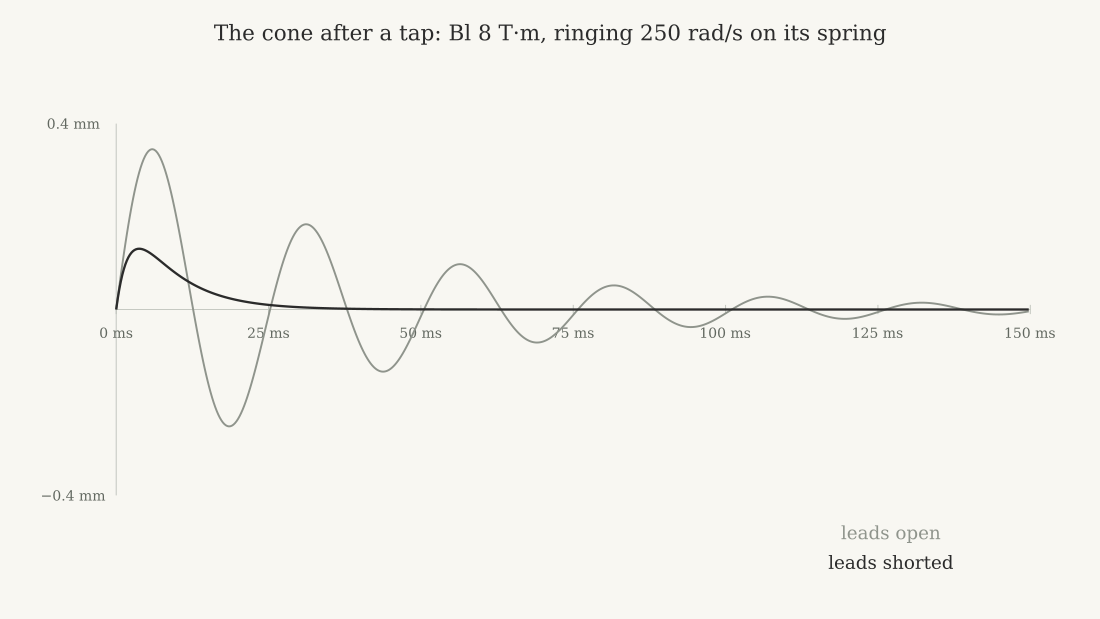

In [9]:
ringdown_still(s)

Spec sheets measure this as Qes: the ring rate times the moving mass, over Bl²/R. It's how many radians of ringing the electrical drag needs to take the swing's energy down by a factor of e. Many sheets write the ring rate as 2π f_s, a turn per cycle. A smaller Qes means more grip, and doubling Bl takes it to a quarter.

In [10]:
print(f'drag, leads shorted   {drag(s, SHORT):.3g} N per m/s')
print(f'Qms, the suspension   {q_mechanical(s):.2g}')
print(f'Qes, the circuit      {q_electrical(s):.2g}')

drag, leads shorted   10.8 N per m/s
Qms, the suspension   5
Qes, the circuit      0.46


## Turn it yourself

The sliders set the field and the windings, and the menu picks what to compare against open leads. The sliders need a running kernel.

In [11]:
explore(s)

## Rocks on the trail

- Bl changes as the coil moves. Push the cone far enough out and part of the wire leaves the gap, so Bl falls off at big swings. A spec sheet quotes Bl at rest, and large-signal tests like Klippel's measure it as a function of the coil's place. A bare ring's capture changing with its pose is the same story.
- Spec sheets often write it BL. Either way, the l is a length.
- An amplifier's "damping factor" is about the drag above. The coil's own resistance sits in the circuit no matter what, so once the amplifier's output resistance is small next to it, more damping factor buys very little.

## Sources

- [Klippel, Transducer parameter identification](https://docs.klippel.de/db-lab/latest/transducer-parameter-identification/fastlsi/fastlsi.html): force Bl·i, back-EMF Bl·v, and Bl varying with displacement.
- [Thiele–Small parameter equations (Audio Judgement)](https://audiojudgement.com/thiele-small-parameters-equations/): Qes in terms of Re, Bl, and the resonance.